# WY2021 Icefield grids at the radar snow-model sites

TKG2, TKG3, C161, TKG4 and DG1 are the five sites with radar-site SNOWPACK runs. The first map shows their locations in the full Icefield extent. The side-by-side overview compares the available grids over the same Icefield extent. The close-up outlines the containing native HRRR-AK, 1,000 m and 500 m cells. Downscaled panels appear as the terrain files become available.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
folders = (cwd, cwd / "downscaling", cwd / "jif_snow_modeling" / "downscaling")
folder = next((p for p in folders if (p / "radar_icefield_comparison.py").is_file()), None)
if folder is None:
    raise FileNotFoundError("Open the notebook from the repos workspace or JIF repository.")
sys.path.insert(0, str(folder))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import xarray as xr
from radar_icefield_comparison import NATIVE, RUN, SURFACE, elevation_table, geometry, load_forcing, radar_sites

sites = radar_sites()
grids, cells = geometry(sites)
output = folder / "outputs"

from matplotlib.colors import Normalize
from matplotlib.patches import Polygon

site_colors = dict(zip(sites.index, ["#b93332","#2278b5","#854cb0","#b87200","#13856b"]))
cmap = "terrain"
norm = Normalize(0, max(np.nanmax(z) for _, _, z in grids.values()))
bounds = (sites.x.min()-4000, sites.x.max()+4000, sites.y.min()-4000, sites.y.max()+4000)


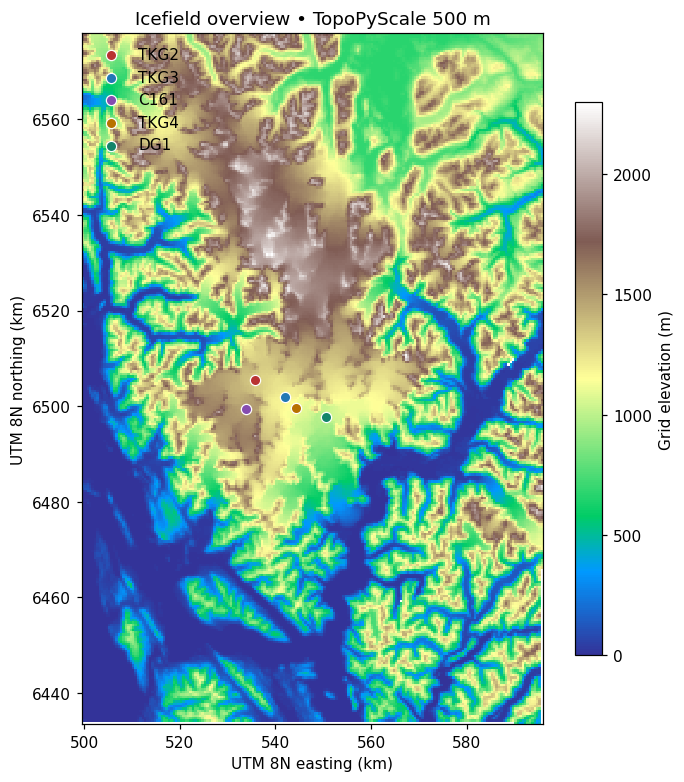

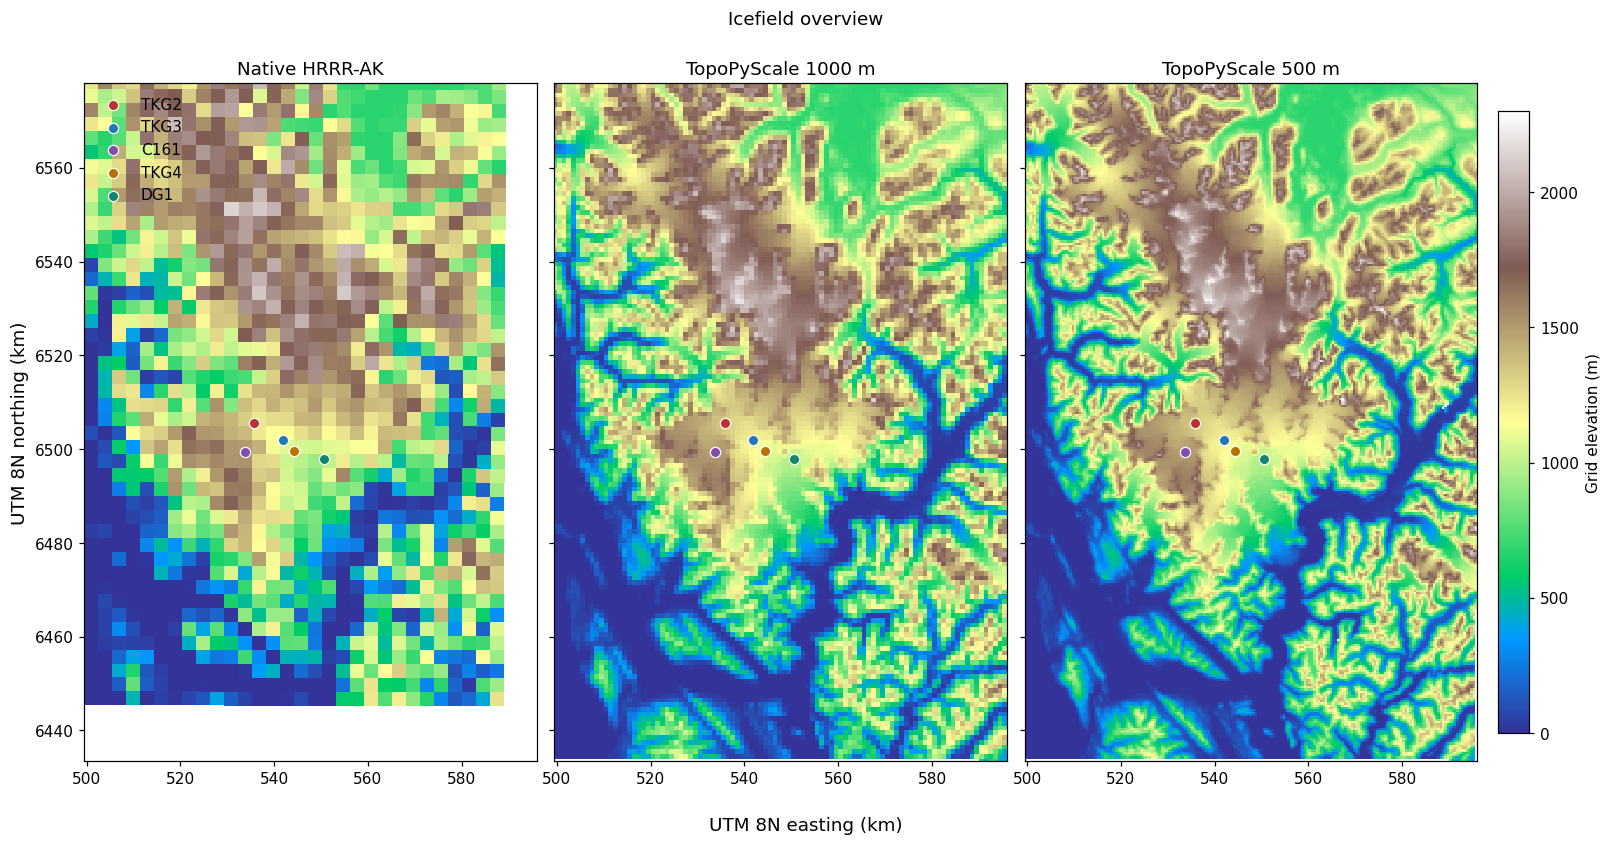

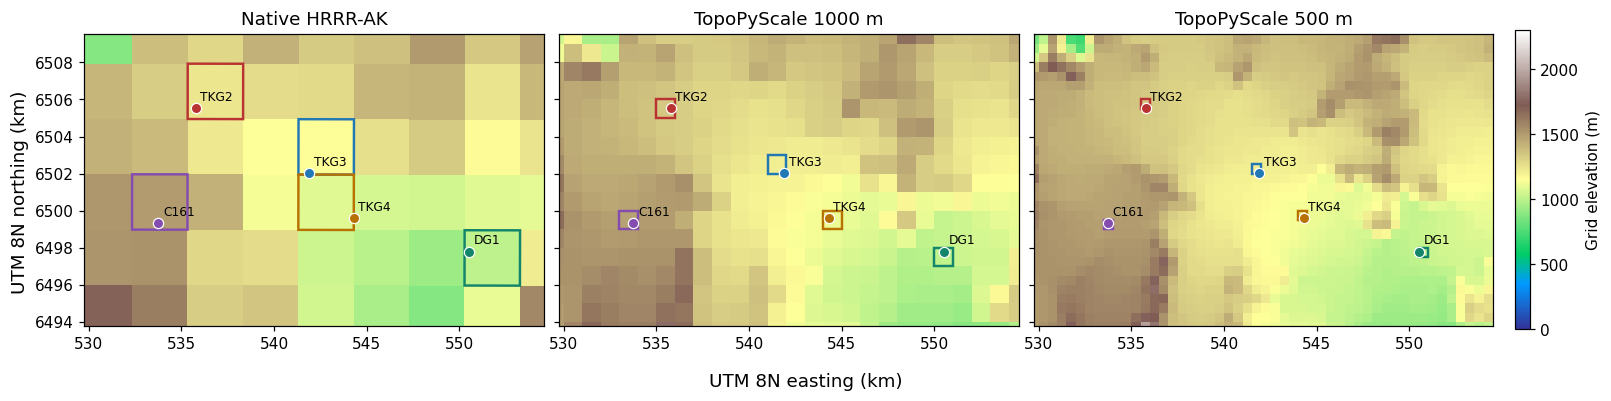

In [2]:
def draw_sites(ax, annotate=False):
    for site, row in sites.iterrows():
        ax.scatter(row.x/1000, row.y/1000, c=site_colors[site], s=45,
                   edgecolor="white", linewidth=.8, zorder=4, label=site)
        if annotate:
            ax.annotate(site, (row.x/1000,row.y/1000), xytext=(3,5),
                        textcoords="offset points", fontsize=8, zorder=5)

def base_map(ax, label, grid, zoom, scale=norm, palette=cmap, satellite=None):
    x, y, z = grid
    if satellite is None:
        image = ax.pcolormesh(x/1000, y/1000, z, cmap=palette, norm=scale, shading="flat")
    else:
        imagery, image_extent = satellite
        image = ax.imshow(imagery, extent=image_extent, origin="upper")
        # Slice to the window plus a margin for cells crossing the view boundary.
        west, east, south, north = bounds
        nearby = ((x >= west - 4000) & (x <= east + 4000)
                  & (y >= south - 4000) & (y <= north + 4000))
        rows, cols = np.nonzero(nearby)
        if rows.size:
            r0, r1 = rows.min(), rows.max()
            c0, c1 = cols.min(), cols.max()
            edges = np.s_[r0:r1 + 1, c0:c1 + 1]
            mesh = ax.pcolormesh(
                x[edges] / 1000, y[edges] / 1000, z[r0:r1, c0:c1],
                shading="flat", edgecolors=(.06, .11, .16, .68), linewidth=.42, zorder=2,
            )
            mesh.set_array(None)
            mesh.set_facecolor("none")
    ax.set(title=label, aspect="equal")
    draw_sites(ax, annotate=zoom)
    if zoom:
        for row in cells[cells.grid == label].itertuples():
            i, j = row.row, row.col
            corners = [(i,j),(i,j+1),(i+1,j+1),(i+1,j)]
            ax.add_patch(Polygon([(x[i,j]/1000,y[i,j]/1000) for i,j in corners],
                                 fill=False, edgecolor=site_colors[row.site], linewidth=1.6))
    return image


def compare_maps(maps, extent, units, *, zoom=False, scale=norm, palette=cmap,
                 title=None, legend=False, satellite=None):
    west, east, south, north = extent
    height = 4.5 * (north - south) / (east - west)
    fig, axes = plt.subplots(
        1, len(maps), figsize=(4.5 * len(maps) + (1 if units else 0), height + .8),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
        gridspec_kw={"wspace": .01},
    )
    fig.get_layout_engine().set(w_pad=.025, h_pad=.025)
    for ax, (label, grid) in zip(axes.flat, maps.items()):
        image = base_map(ax, label, grid, zoom, scale, palette, satellite)
    axes[0, 0].set(xlim=(west / 1000, east / 1000), ylim=(south / 1000, north / 1000))
    fig.supxlabel("UTM 8N easting (km)")
    fig.supylabel("UTM 8N northing (km)")
    if title:
        fig.suptitle(title)
    if legend:
        axes[0, 0].legend(frameon=False, loc="upper left")
    if units:
        fig.colorbar(image, ax=list(axes.flat), label=units, shrink=.8, pad=.015)
    if satellite is not None:
        axes[0, 0].text(.02, .02, "Imagery © Esri and contributors",
                        transform=axes[0, 0].transAxes, fontsize=7, zorder=6,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=.9))
    plt.show()


label = "TopoPyScale 500 m" if "TopoPyScale 500 m" in grids else next(reversed(grids))
fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
image = base_map(ax, f"Icefield overview • {label}", grids[label], False)
ax.set(xlabel="UTM 8N easting (km)", ylabel="UTM 8N northing (km)")
ax.legend(frameon=False, loc="upper left")
fig.colorbar(image, ax=ax, label="Grid elevation (m)", shrink=.8)
plt.show()

# Use the original Icefield overview footprint for every overview panel.
overview_x, overview_y, _ = grids[label]
overview_bounds = (overview_x.min(), overview_x.max(), overview_y.min(), overview_y.max())
compare_maps(grids, overview_bounds, "Grid elevation (m)", title="Icefield overview", legend=True)
compare_maps(grids, bounds, "Grid elevation (m)", zoom=True)

## Satellite close-up at the radar sites

The same Esri World Imagery scene and map extent appear in each panel. The dark lines trace grid-cell boundaries, and the colored outlines mark the cells containing the radar sites.

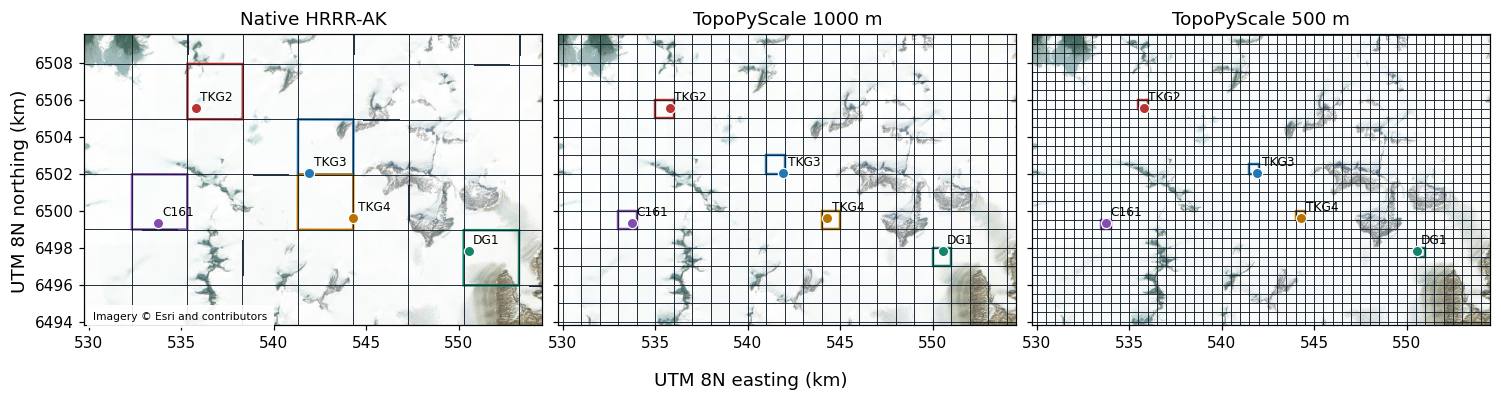

In [3]:
import hashlib
import io
import json
from urllib.parse import urlencode
from urllib.request import urlopen

from PIL import Image

cache = folder.parent / "data" / "basemaps"
west, east, south, north = bounds
utm = 32608

# Reuse the highest-resolution cached Esri scene that covers the entire view.
cached_scenes = []
for metadata_path in sorted(cache.glob("esri_*.json")):
    image_path = metadata_path.with_suffix(".jpg")
    if not image_path.is_file():
        continue
    metadata = json.loads(metadata_path.read_text())
    extent = metadata["extent"]
    crs = extent["spatialReference"]
    if (crs.get("latestWkid", crs.get("wkid")) == utm
            and extent["xmin"] <= west and extent["xmax"] >= east
            and extent["ymin"] <= south and extent["ymax"] >= north):
        pixel_width = (extent["xmax"] - extent["xmin"]) / metadata["width"]
        cached_scenes.append((pixel_width, image_path, extent))

if cached_scenes:
    _, image_path, extent = min(cached_scenes)
else:
    service = "https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer"
    width = 1600
    height = round(width * (north - south) / (east - west))
    params = urlencode(dict(bbox=f"{west},{south},{east},{north}", bboxSR=utm, imageSR=utm,
                            size=f"{width},{height}", format="jpg", f="json"))
    with urlopen(f"{service}/export?{params}", timeout=60) as response:
        metadata = json.load(response)
    if "error" in metadata:
        raise RuntimeError(f'Esri World Imagery export failed: {metadata["error"]}')
    with urlopen(metadata["href"], timeout=60) as response:
        image_bytes = response.read()
    with Image.open(io.BytesIO(image_bytes)) as downloaded:
        downloaded.verify()
    extent = metadata["extent"]
    cache.mkdir(parents=True, exist_ok=True)
    image_path = cache / f"esri_{hashlib.sha256(params.encode()).hexdigest()[:16]}.jpg"
    image_path.write_bytes(image_bytes)
    image_path.with_suffix(".json").write_text(json.dumps(metadata, indent=2))

with Image.open(image_path) as image:
    imagery = np.asarray(image.convert("RGB"))
image_extent = [extent[key] / 1000 for key in ("xmin", "xmax", "ymin", "ymax")]
compare_maps(grids, bounds, None, zoom=True, satellite=(imagery, image_extent))

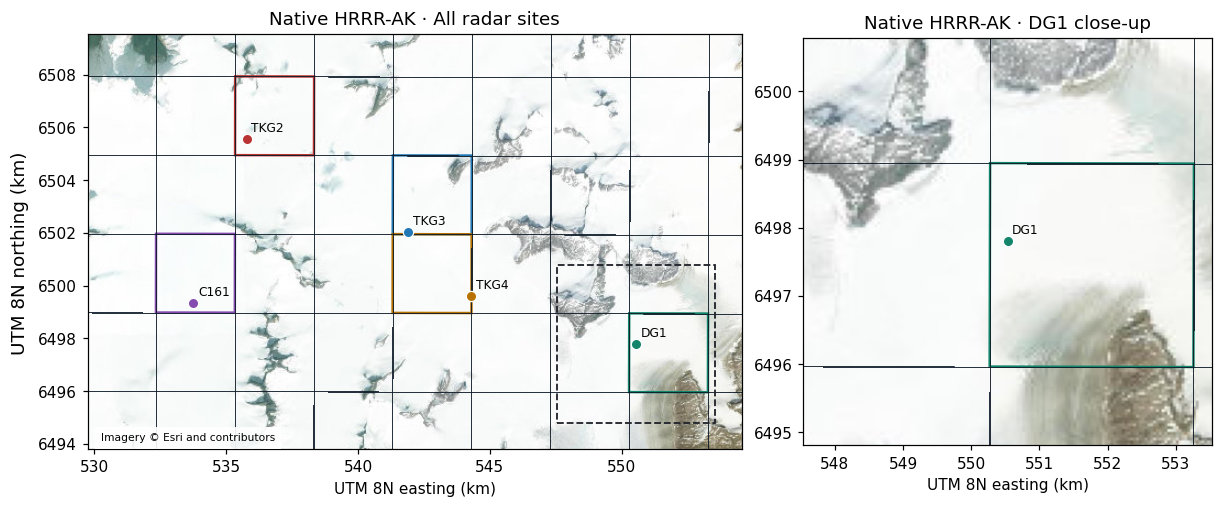

In [4]:
native_grid = grids[NATIVE]
native_x, native_y, _ = native_grid
dg1 = sites.loc["DG1"]
row, col = cells.loc[(cells.grid == NATIVE) & (cells.site == "DG1"), ["row", "col"]].iloc[0]
cell_edges = np.s_[row:row+2, col:col+2]
# A DG1-centered window about two native cells wide and two cells tall.
half_width = np.ptp(native_x[cell_edges])
half_height = np.ptp(native_y[cell_edges])
dg1_bounds = (dg1.x - half_width, dg1.x + half_width,
              dg1.y - half_height, dg1.y + half_height)

fig, (overview_ax, zoom_ax) = plt.subplots(
    1, 2, figsize=(11, 4.5), width_ratios=(1.6, 1), layout="constrained"
)
for ax, title, extent in (
    (overview_ax, "Native HRRR-AK · All radar sites", bounds),
    (zoom_ax, "Native HRRR-AK · DG1 close-up", dg1_bounds),
):
    base_map(ax, NATIVE, native_grid, zoom=True, satellite=(imagery, image_extent))
    west, east, south, north = (edge / 1000 for edge in extent)
    ax.set(title=title, xlim=(west, east), ylim=(south, north))
    ax.set_xlabel("UTM 8N easting (km)")
fig.supylabel("UTM 8N northing (km)")
west, east, south, north = (edge / 1000 for edge in dg1_bounds)
overview_ax.add_patch(Polygon(
    [(west, south), (east, south), (east, north), (west, north)],
    fill=False, edgecolor="#20242a", linestyle="--", linewidth=1.2, zorder=5,
))
overview_ax.text(.02, .02, "Imagery © Esri and contributors",
                 transform=overview_ax.transAxes, fontsize=7, zorder=6,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=.9))
plt.show()

## Hourly temperature snapshot

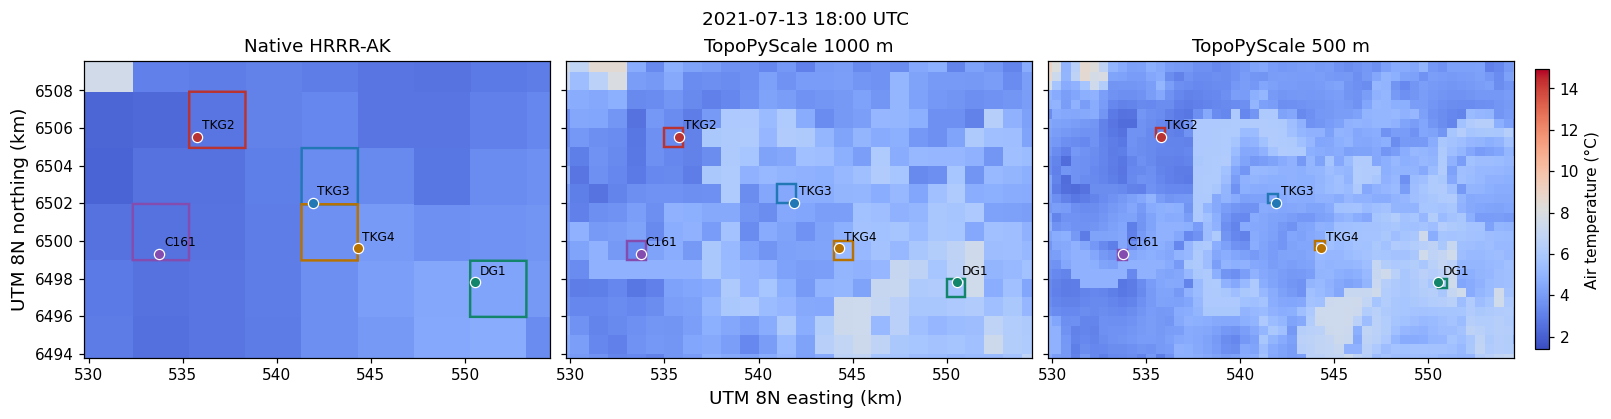

In [5]:
hour = pd.Timestamp("2021-07-13T18:00")
ready_grids = [(m,f"TopoPyScale {m} m") for m in (1000,500)
               if (RUN / f"{m}m/forcing.nc").is_file() and f"TopoPyScale {m} m" in grids]
if SURFACE.is_file() and ready_grids:
    with xr.open_dataset(SURFACE) as source:
        temperatures = {NATIVE: (*grids[NATIVE][:2], source.temp.sel(time=hour).values-273.15)}
    for m,label in ready_grids:
        with xr.open_dataset(RUN / f"{m}m/terrain.nc") as terrain:
            cell = terrain.cell_id.values
        with xr.open_dataset(RUN / f"{m}m/forcing.nc") as forcing:
            t = forcing.t.sel(time=hour).values-273.15
        image = np.full(cell.shape,np.nan)
        active = cell >= 0
        image[active] = t[cell[active]]
        temperatures[label] = (*grids[label][:2],image)
    scale = Normalize(min(np.nanmin(t) for _,_,t in temperatures.values()),
                      max(np.nanmax(t) for _,_,t in temperatures.values()))
    compare_maps(temperatures, bounds, "Air temperature (°C)", zoom=True,
                 scale=scale, palette="coolwarm", title=f"{hour:%Y-%m-%d %H:%M} UTC")
else:
    print("Temperature map will appear when a downscaled forcing file finishes.")


## Site and grid-cell elevations

The site elevations come from the existing SNOWPACK run inputs. TKG4 uses the established model point and its 1,120 m elevation. The native HRRR-AK value is the WY2021 median at the containing native cell, with the minimum and maximum shown separately. The downscaled values are cell-average ArcticDEM elevations. Δ is grid-cell elevation minus site elevation. Vertical datums have not been independently reconciled. Blank values indicate missing coverage or terrain.

In [6]:
display(elevation_table(cells, output))

,Site elevation (m),Native HRRR-AK elevation (m),Native HRRR-AK Δ (m),Native min–max (m),TopoPyScale 1000 m elevation (m),TopoPyScale 1000 m Δ (m),TopoPyScale 500 m elevation (m),TopoPyScale 500 m Δ (m)
site,,,,,,,,
TKG2,1326.0,1306.5,-19.5,1234.8–1306.5,1343.0,17.0,1339.9,13.9
TKG3,1203.0,1246.1,43.1,1152.9–1246.1,1210.5,7.5,1205.5,2.5
C161,1483.0,1477.3,-5.7,1477.3–1494.6,1481.2,-1.8,1485.9,2.9
TKG4,1120.0,1156.2,36.2,1078.6–1156.2,1112.0,-8.0,1116.7,-3.3
DG1,1018.0,1041.8,23.8,1003.4–1041.8,1007.6,-10.4,1015.6,-2.4


## Radar site and grid-cell elevations

The black bars show the site elevations used by SNOWPACK. Grid-bar labels give the elevation difference from the site in meters (grid minus site).

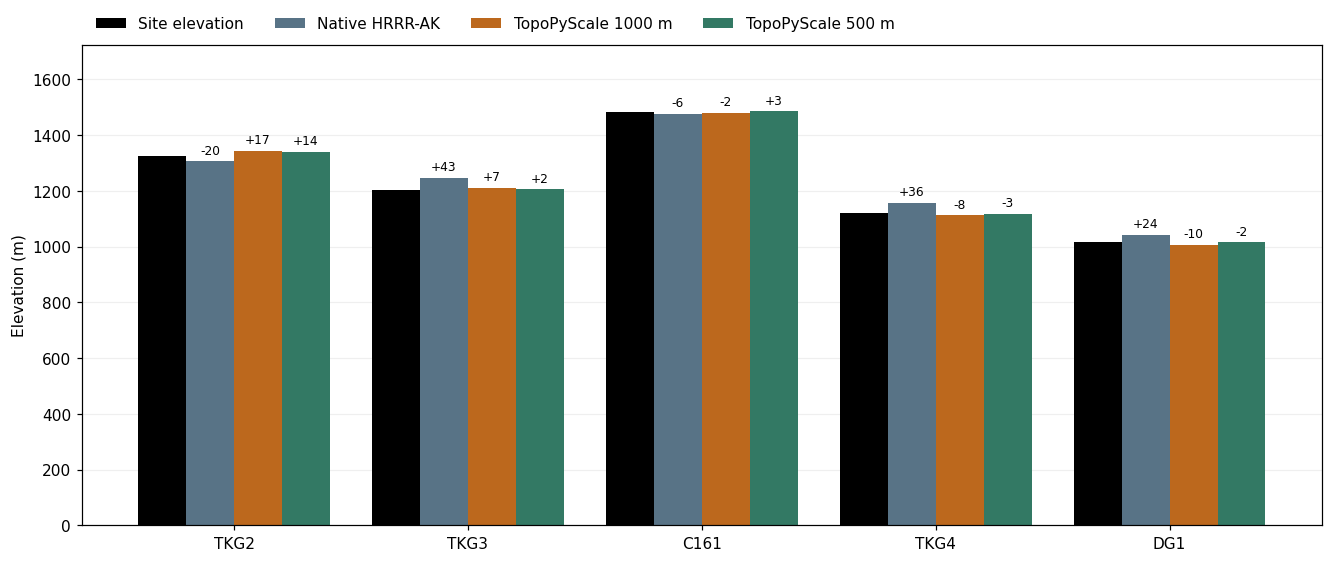

In [7]:
grid_elevations = cells.pivot(index="site", columns="grid", values="grid_elevation_m")
site_elevations = sites.site_elevation_m
grid_elevations = grid_elevations.reindex(index=sites.index, columns=list(grids))
series = {"Site elevation": site_elevations, **grid_elevations}
bar_colors = ("black", "#587386", "#bc681d", "#337964")
positions = np.arange(len(sites))
width = .82 / len(series)

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
for i, ((label, values), color) in enumerate(zip(series.items(), bar_colors)):
    offset = (i - (len(series) - 1) / 2) * width
    bars = ax.bar(positions + offset, values, width, color=color, label=label)
    if i:
        differences = values - site_elevations
        ax.bar_label(bars, labels=[f"{delta:+.0f}" if np.isfinite(delta) else ""
                                  for delta in differences], padding=3, fontsize=8)
ax.set(xticks=positions, xticklabels=sites.index, ylabel="Elevation (m)")
ax.set_ylim(0, 1.16 * max(site_elevations.max(), grid_elevations.max().max()))
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.legend(ncol=len(series), loc="lower left", bbox_to_anchor=(0, 1), frameon=False)
plt.show()